### INSTALLATION & IMPORTS

In [6]:
!pip install timm -q
 
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
from PIL import Image
from pathlib import Path
import numpy as np
import timm
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score, confusion_matrix,
                              roc_auc_score, roc_curve)
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from tqdm import tqdm
import warnings
import random
 
warnings.filterwarnings("ignore")
 
# Reproductibilité totale
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
 
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")
print(f"GPU    : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'Non disponible'}")
 

Device : cuda
GPU    : Tesla T4


### Chargement brut des donnees

In [7]:
DATA_ROOT  = "/kaggle/input/datasets/faber24/lcc-fasd/LCC_FASD"

IMG_SIZE   = 224
BATCH_SIZE = 32
MEAN       = [0.485, 0.456, 0.406]
STD        = [0.229, 0.224, 0.225]
 
 
class LCCFASDDataset(Dataset):
    """
    Charge les chemins et labels depuis un dossier split.
    Version simplifiée : une seule transformation appliquée à toutes les images.
    Le déséquilibre est géré par class_weights dans la loss (suffisant pour 5.78x).
    """
    def __init__(self, root_dir, transform=None):
        self.transform = transform
        self.samples   = []
        self.labels    = []
 
        for label_name, label_idx in [("spoof", 0), ("real", 1)]:
            folder = Path(root_dir) / label_name
            for ext in ["*.jpg", "*.jpeg", "*.png"]:
                for img_path in sorted(folder.glob(ext)):
                    self.samples.append(str(img_path))
                    self.labels.append(label_idx)
 
        n_spoof = self.labels.count(0)
        n_real  = self.labels.count(1)
        ratio   = n_spoof / max(n_real, 1)
        print(f"  [{Path(root_dir).name:<30}]  "
              f"total={len(self.samples):>5}  |  "
              f"spoof={n_spoof:>5}  |  real={n_real:>5}  |  ratio={ratio:.2f}")
 
    def __len__(self):
        return len(self.samples)
 
    def __getitem__(self, idx):
        img   = Image.open(self.samples[idx]).convert("RGB")
        label = self.labels[idx]
        if self.transform is not None:
            img = self.transform(img)
        return img, label
 
 
# Chargement sans transformées (pour l'analyse brute de la Cellule 3)
print("Chargement des datasets (sans transformées)...")
train_ds_raw = LCCFASDDataset(f"{DATA_ROOT}/LCC_FASD_training")
val_ds_raw   = LCCFASDDataset(f"{DATA_ROOT}/LCC_FASD_development")
test_ds_raw  = LCCFASDDataset(f"{DATA_ROOT}/LCC_FASD_evaluation")
 

Chargement des datasets (sans transformées)...
  [LCC_FASD_training             ]  total= 8299  |  spoof= 7076  |  real= 1223  |  ratio=5.79
  [LCC_FASD_development          ]  total= 2948  |  spoof= 2543  |  real=  405  |  ratio=6.28
  [LCC_FASD_evaluation           ]  total= 7580  |  spoof= 7266  |  real=  314  |  ratio=23.14


### Analyse et visualisation de l'équilibre du dataset


  ANALYSE DE L'ÉQUILIBRE — LCC-FASD

  [Training]
    Total           :  8,299
    Spoof (label 0) :  7,076  (85.3%)
    Real  (label 1) :  1,223  (14.7%)
    Ratio spoof/real: 5.786
    Statut          : Fort déséquilibre (SPOOF majoritaire)

  [Development (val)]
    Total           :  2,948
    Spoof (label 0) :  2,543  (86.3%)
    Real  (label 1) :    405  (13.7%)
    Ratio spoof/real: 6.279
    Statut          : Fort déséquilibre (SPOOF majoritaire)

  [Evaluation (test)]
    Total           :  7,580
    Spoof (label 0) :  7,266  (95.9%)
    Real  (label 1) :    314  (4.1%)
    Ratio spoof/real: 23.140
    Statut          : Fort déséquilibre (SPOOF majoritaire)


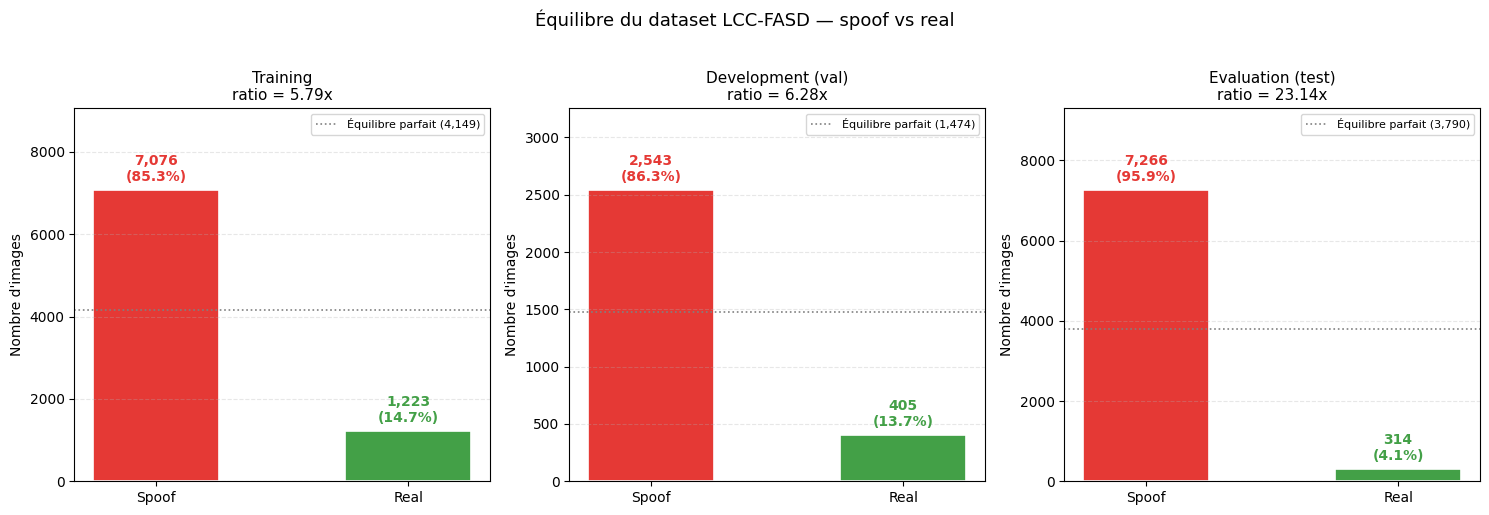

Figure sauvegardée : dataset_balance.png


In [8]:
def analyze_split(ds, split_name):
    labels  = np.array(ds.labels)
    n_spoof = int((labels == 0).sum())
    n_real  = int((labels == 1).sum())
    total   = len(labels)
    ratio   = n_spoof / max(n_real, 1)
 
    if ratio < 1.10:
        status = "Équilibré"
    elif ratio < 2.0:
        status = "Léger déséquilibre (SPOOF majoritaire)"
    elif ratio < 5.0:
        status = "Déséquilibre modéré (SPOOF majoritaire)"
    else:
        status = "Fort déséquilibre (SPOOF majoritaire)"
 
    return dict(name=split_name, n_spoof=n_spoof, n_real=n_real,
                total=total, ratio=ratio, status=status)
 
 
splits_info = [
    analyze_split(train_ds_raw, "Training"),
    analyze_split(val_ds_raw,   "Development (val)"),
    analyze_split(test_ds_raw,  "Evaluation (test)"),
]
 
print("\n" + "=" * 65)
print("  ANALYSE DE L'ÉQUILIBRE — LCC-FASD")
print("=" * 65)
for s in splits_info:
    print(f"\n  [{s['name']}]")
    print(f"    Total           : {s['total']:>6,}")
    print(f"    Spoof (label 0) : {s['n_spoof']:>6,}  ({100*s['n_spoof']/s['total']:.1f}%)")
    print(f"    Real  (label 1) : {s['n_real']:>6,}  ({100*s['n_real']/s['total']:.1f}%)")
    print(f"    Ratio spoof/real: {s['ratio']:.3f}")
    print(f"    Statut          : {s['status']}")
 
# Visualisation
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Équilibre du dataset LCC-FASD — spoof vs real", fontsize=13, y=1.02)
COLORS = {"Spoof": "#E53935", "Real": "#43A047"}
 
for ax, s in zip(axes, splits_info):
    vals  = [s["n_spoof"], s["n_real"]]
    names = ["Spoof", "Real"]
    bars  = ax.bar(names, vals,
                   color=[COLORS["Spoof"], COLORS["Real"]],
                   width=0.5, edgecolor="white", linewidth=1.2)
    ax.set_title(f"{s['name']}\nratio = {s['ratio']:.2f}x", fontsize=11)
    ax.set_ylabel("Nombre d'images")
    ax.set_ylim(0, max(vals) * 1.28)
    ax.grid(axis="y", alpha=0.3, linestyle="--")
    for bar, v, n in zip(bars, vals, names):
        pct = 100 * v / s["total"]
        ax.text(bar.get_x() + bar.get_width() / 2,
                v + max(vals) * 0.02,
                f"{v:,}\n({pct:.1f}%)",
                ha="center", va="bottom", fontsize=10,
                fontweight="bold", color=COLORS[n])
    eq = s["total"] / 2
    ax.axhline(eq, color="gray", linestyle=":", linewidth=1.2,
               label=f"Équilibre parfait ({int(eq):,})")
    ax.legend(fontsize=8)
 
plt.tight_layout()
plt.savefig("dataset_balance.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure sauvegardée : dataset_balance.png")
 

### Data augmentation minimale + DataLoaders

In [9]:
# Transformation entraînement : augmentation légère uniforme
train_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=5),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
 
# Validation et test : aucune augmentation
val_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
 
print("Application des transformées...")
train_ds = LCCFASDDataset(f"{DATA_ROOT}/LCC_FASD_training",    transform=train_tf)
val_ds   = LCCFASDDataset(f"{DATA_ROOT}/LCC_FASD_development", transform=val_tf)
test_ds  = LCCFASDDataset(f"{DATA_ROOT}/LCC_FASD_evaluation",  transform=val_tf)
 
# DataLoaders sans WeightedSampler — shuffle normal
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=True
)
val_loader  = DataLoader(val_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
 
# Poids de classe pour la loss (gestion du déséquilibre 5.78x)
n_spoof_tr    = train_ds.labels.count(0)
n_real_tr     = train_ds.labels.count(1)
w_raw         = torch.tensor([1.0 / n_spoof_tr, 1.0 / n_real_tr])
class_weights = (w_raw / w_raw.sum() * 2).to(DEVICE)
 
print(f"\nPoids de classe  ->  spoof: {class_weights[0]:.4f}  |  real: {class_weights[1]:.4f}")
print(f"Batches          ->  train: {len(train_loader)}  |  val: {len(val_loader)}  |  test: {len(test_loader)}")
print(f"Exemples/époque train : {len(train_loader) * BATCH_SIZE}  (dataset complet)")
 

Application des transformées...
  [LCC_FASD_training             ]  total= 8299  |  spoof= 7076  |  real= 1223  |  ratio=5.79
  [LCC_FASD_development          ]  total= 2948  |  spoof= 2543  |  real=  405  |  ratio=6.28
  [LCC_FASD_evaluation           ]  total= 7580  |  spoof= 7266  |  real=  314  |  ratio=23.14

Poids de classe  ->  spoof: 0.2947  |  real: 1.7053
Batches          ->  train: 260  |  val: 93  |  test: 237
Exemples/époque train : 8320  (dataset complet)


### Modele Swin Transformer : definition des 5 strategies

In [10]:
# Justification du choix de Swin-Tiny :
#   Architecture Transformer à fenêtres glissantes hiérarchiques (4 layers).
#   Pré-entraîné ImageNet-1K -> transfert direct vers la détection de spoofing.
#   Ref : Liu et al. 2021 — "Swin Transformer" (ICCV)
#
# Les 5 stratégies sont définies mais on n'entraîne que fine_tune_3
# (meilleure stratégie identifiée lors de l'expérience sans augmentation).
 
def build_model(strategy: str) -> nn.Module:
    model = timm.create_model(
        "swin_tiny_patch4_window7_224",
        pretrained=True,
        num_classes=2
    )
 
    # Étape 1 : tout geler
    for p in model.parameters():
        p.requires_grad = False
 
    # Étape 2 : dégeler selon la stratégie
    if strategy == "fine_tune_all":
        for p in model.parameters():
            p.requires_grad = True
 
    elif strategy == "fine_tune_3":
        # Layers 1, 2, 3 + norm + head
        for i in [1, 2, 3]:
            for p in model.layers[i].parameters():
                p.requires_grad = True
        for p in model.norm.parameters(): p.requires_grad = True
        for p in model.head.parameters(): p.requires_grad = True
 
    elif strategy == "fine_tune_2":
        for i in [2, 3]:
            for p in model.layers[i].parameters():
                p.requires_grad = True
        for p in model.norm.parameters(): p.requires_grad = True
        for p in model.head.parameters(): p.requires_grad = True
 
    elif strategy == "fine_tune_1":
        for p in model.layers[3].parameters(): p.requires_grad = True
        for p in model.norm.parameters():      p.requires_grad = True
        for p in model.head.parameters():      p.requires_grad = True
 
    else:  # freeze_all
        for p in model.head.parameters():
            p.requires_grad = True
 
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    print(f"  [{strategy:<15}]  entraînables : {n_train:>9,} / {n_total:,} "
          f"({100 * n_train / n_total:.1f}%)")
 
    return model.to(DEVICE)

### Entrainement comparatif + selection du meilleur modele

In [ ]:
class LabelSmoothingCE(nn.Module):
    """Cross-Entropy avec label smoothing + pondération de classe."""
    def __init__(self, smoothing=0.1, weight=None):
        super().__init__()
        self.smoothing = smoothing
        self.weight    = weight
 
    def forward(self, logits, targets):
        n_classes = logits.size(1)
        with torch.no_grad():
            smooth_targets = torch.full_like(logits, self.smoothing / (n_classes - 1))
            smooth_targets.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)
        log_prob   = torch.log_softmax(logits, dim=1)
        per_sample = -(smooth_targets * log_prob).sum(dim=1)
        if self.weight is not None:
            sample_w = self.weight[targets]
            return (per_sample * sample_w).sum() / sample_w.sum()
        return per_sample.mean()
 
 
def train_one_epoch(model, loader, optimizer, criterion, scaler=None):
    model.train()
    loss_sum, correct, n = 0.0, 0, 0
    for imgs, labels in tqdm(loader, desc="  Train", leave=False):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        if scaler:
            with torch.cuda.amp.autocast():
                out  = model(imgs)
                loss = criterion(out, labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            out  = model(imgs)
            loss = criterion(out, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        loss_sum += loss.item() * imgs.size(0)
        correct  += (out.argmax(1) == labels).sum().item()
        n        += imgs.size(0)
    return loss_sum / n, correct / n
 
 
def evaluate(model, loader):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in tqdm(loader, desc="  Eval", leave=False):
            imgs   = imgs.to(DEVICE)
            logits = model(imgs)
            probs  = torch.softmax(logits, dim=1)[:, 1]
            all_preds.extend(logits.argmax(1).cpu().numpy())
            all_labels.extend(labels.numpy())
            all_probs.extend(probs.cpu().numpy())
 
    acc  = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, average="weighted", zero_division=0)
    rec  = recall_score(all_labels, all_preds, average="weighted", zero_division=0)
    f1   = f1_score(all_labels, all_preds, average="weighted", zero_division=0)
    try:
        auc = roc_auc_score(all_labels, all_probs)
    except Exception:
        auc = 0.0
    return acc, prec, rec, f1, auc, all_preds, all_labels, all_probs
 
 
def train_strategy(strategy: str, num_epochs: int = 10):
    print(f"\n{'='*60}")
    print(f"  Stratégie : {strategy}")
    print(f"{'='*60}")
 
    model     = build_model(strategy)
    criterion = LabelSmoothingCE(smoothing=0.1, weight=class_weights)
    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=2e-4, weight_decay=1e-4
    )
    scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(
        optimizer, T_0=max(num_epochs // 2, 1), T_mult=1
    )
    scaler = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None
 
    best_f1, best_state = 0.0, None
    history = {"train_loss": [], "train_acc": [], "val_acc": [], "val_f1": [], "val_auc": []}
 
    for epoch in range(1, num_epochs + 1):
        tr_loss, tr_acc              = train_one_epoch(model, train_loader,
                                                       optimizer, criterion, scaler)
        acc, prec, rec, f1, auc, _, _, _ = evaluate(model, val_loader)
        scheduler.step()
 
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(acc)
        history["val_f1"].append(f1)
        history["val_auc"].append(auc)
 
        flag = "  <- best" if f1 > best_f1 else ""
        print(f"  Ep {epoch:02d}/{num_epochs} | loss={tr_loss:.4f} | "
              f"train={tr_acc*100:.2f}% | val={acc*100:.2f}% | "
              f"F1={f1*100:.2f}% | AUC={auc:.4f}{flag}")
 
        if f1 > best_f1:
            best_f1    = f1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
 
    model.load_state_dict(best_state)
    acc, prec, rec, f1, auc, preds, labels, probs = evaluate(model, test_loader)
    print(f"\n  [TEST]  Acc={acc*100:.2f}%  Prec={prec*100:.2f}%  "
          f"Rec={rec*100:.2f}%  F1={f1*100:.2f}%  AUC={auc:.4f}")
 
    torch.save(model.state_dict(), f"model_{strategy}.pth")
    return model, history, dict(accuracy=acc, precision=prec, recall=rec,
                                f1=f1, auc=auc, preds=preds,
                                labels=labels, probs=probs)
 
 
# Lancement de la comparaison des 5 stratégies
STRATEGIES  = ["freeze_all", "fine_tune_1", "fine_tune_2", "fine_tune_3", "fine_tune_all"]
NUM_EPOCHS  = 10
all_results = {}
 
for strat in STRATEGIES:
    model, history, metrics = train_strategy(strat, num_epochs=NUM_EPOCHS)
    all_results[strat] = dict(model=model, history=history, metrics=metrics)
 
# Sélection du meilleur modèle selon F1 sur test
best_strat   = max(all_results, key=lambda s: all_results[s]["metrics"]["f1"])
best_model   = all_results[best_strat]["model"]
best_metrics = all_results[best_strat]["metrics"]
 
print(f"\n{'='*60}")
print(f"  Meilleur modèle : {best_strat}")
print(f"  Acc test        : {best_metrics['accuracy']*100:.2f}%")
print(f"  F1 test         : {best_metrics['f1']*100:.2f}%")
print(f"  AUC test        : {best_metrics['auc']:.4f}")
print(f"{'='*60}")
 


  Stratégie : freeze_all


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

  [freeze_all     ]  entraînables :     1,538 / 27,520,892 (0.0%)


  Ep 01/10 | loss=0.5506 | train=83.54% | val=88.33% | F1=89.08% | AUC=0.9172  <- best


  Ep 02/10 | loss=0.4703 | train=91.05% | val=87.92% | F1=88.78% | AUC=0.9278


...

  Ep 07/10 | loss=0.3710 | train=98.16% | val=92.37% | F1=92.91% | AUC=0.9851


  Ep 08/10 | loss=0.3377 | train=99.34% | val=88.87% | F1=89.89% | AUC=0.9717


  Ep 09/10 | loss=0.3290 | train=99.80% | val=95.59% | F1=95.65% | AUC=0.9865


  Ep 10/10 | loss=0.3262 | train=99.94% | val=95.79% | F1=95.84% | AUC=0.9862



  [TEST]  Acc=98.15%  Prec=98.30%  Rec=98.15%  F1=98.21%  AUC=0.9672

  Meilleur modèle : fine_tune_3
  Acc test        : 98.61%
  F1 test         : 98.56%
  AUC test        : 0.9472


### Attaques adversariales FGSM et PGD AVANT Adversarial Training

In [ ]:
EPS   = 0.03
ALPHA = 0.008
STEPS = 40
 
 
def fgsm_attack(model, imgs, labels, eps=EPS):
    """Fast Gradient Sign Method — Goodfellow et al. 2014"""
    imgs_adv = imgs.clone().detach().to(DEVICE).requires_grad_(True)
    labels   = labels.to(DEVICE)
    loss     = nn.CrossEntropyLoss()(model(imgs_adv), labels)
    model.zero_grad()
    loss.backward()
    return (imgs_adv + eps * imgs_adv.grad.sign()).detach().clamp(-3.0, 3.0)
 
 
def pgd_attack(model, imgs, labels, eps=EPS, alpha=ALPHA, steps=STEPS):
    """Projected Gradient Descent — Madry et al. 2018"""
    imgs   = imgs.to(DEVICE)
    labels = labels.to(DEVICE)
    adv    = imgs + torch.empty_like(imgs).uniform_(-eps, eps)
    adv    = adv.clamp(-3.0, 3.0).detach()
 
    for _ in range(steps):
        adv.requires_grad_(True)
        loss = nn.CrossEntropyLoss()(model(adv), labels)
        model.zero_grad()
        loss.backward()
        with torch.no_grad():
            adv   = adv + alpha * adv.grad.sign()
            delta = torch.clamp(adv - imgs, -eps, eps)
            adv   = (imgs + delta).clamp(-3.0, 3.0).detach()
    return adv
 
 
def eval_adversarial(model, loader, attack_fn, label, **kwargs):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    for imgs, labels in tqdm(loader, desc=f"  {label}"):
        adv = attack_fn(model, imgs, labels, **kwargs)
        with torch.no_grad():
            logits = model(adv)
            probs  = torch.softmax(logits, dim=1)[:, 1]
            all_preds.extend(logits.argmax(1).cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.numpy())
 
    acc  = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, average="weighted", zero_division=0)
    rec  = recall_score(all_labels, all_preds, average="weighted", zero_division=0)
    f1   = f1_score(all_labels, all_preds, average="weighted", zero_division=0)
    try:
        auc = roc_auc_score(all_labels, all_probs)
    except Exception:
        auc = 0.0
 
    print(f"  [{label}]  Acc={acc*100:.2f}%  Prec={prec*100:.2f}%  "
          f"Rec={rec*100:.2f}%  F1={f1*100:.2f}%  AUC={auc:.4f}")
    return dict(accuracy=acc, precision=prec, recall=rec, f1=f1, auc=auc,
                preds=all_preds, labels=all_labels, probs=all_probs)
 
 
print(f"\n--- Attaques sur '{best_strat}' (AVANT Adversarial Training) ---")
fgsm_before = eval_adversarial(best_model, test_loader, fgsm_attack,
                                "FGSM avant AT", eps=EPS)
pgd_before  = eval_adversarial(best_model, test_loader, pgd_attack,
                                "PGD  avant AT", eps=EPS, alpha=ALPHA, steps=STEPS)


--- Attaques sur 'fine_tune_3' (AVANT Adversarial Training) ---


  FGSM avant AT: 100%|██████████| 237/237 [02:12<00:00,  1.78it/s]


  [FGSM avant AT]  Acc=83.89%  Prec=92.76%  Rec=83.89%  F1=87.85%  AUC=0.4041


  PGD  avant AT: 100%|██████████| 237/237 [1:03:15<00:00, 16.01s/it]

  [PGD  avant AT]  Acc=4.09%  Prec=47.62%  Rec=4.09%  F1=7.34%  AUC=0.0027


### Adversarial Training (AT) sur le meilleur modèle

In [ ]:
def adversarial_training(model, epochs=5, eps=EPS, lr=5e-5, pgd_steps=7):
    print(f"\n{'='*60}")
    print(f"  Adversarial Training sur '{best_strat}'")
    print(f"  PGD-{pgd_steps}  |  loss mixte 50/50  |  eps={eps}  |  lr={lr}")
    print(f"{'='*60}")
 
    criterion = LabelSmoothingCE(smoothing=0.05, weight=None)
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler    = torch.cuda.amp.GradScaler() if torch.cuda.is_available() else None
 
    best_f1, best_state = 0.0, None
    at_history = {"val_acc": [], "val_f1": [], "val_auc": [], "adv_acc_train": []}
 
    for epoch in range(1, epochs + 1):
        model.train()
        n_correct_adv, n_total = 0, 0
 
        for imgs, labels in tqdm(train_loader,
                                 desc=f"  AT Ep {epoch}/{epochs}", leave=False):
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
 
            # Génération exemple adversarial PGD-7
            adv = pgd_attack(model, imgs, labels,
                             eps=eps, alpha=eps / 4, steps=pgd_steps)
 
            optimizer.zero_grad()
            if scaler:
                with torch.cuda.amp.autocast():
                    loss = (0.5 * criterion(model(imgs), labels) +
                            0.5 * criterion(model(adv),  labels))
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                loss = (0.5 * criterion(model(imgs), labels) +
                        0.5 * criterion(model(adv),  labels))
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
 
            with torch.no_grad():
                n_correct_adv += (model(adv).argmax(1) == labels).sum().item()
            n_total += imgs.size(0)
 
        scheduler.step()
 
        acc, prec, rec, f1, auc, _, _, _ = evaluate(model, val_loader)
        adv_acc = n_correct_adv / n_total
        at_history["val_acc"].append(acc)
        at_history["val_f1"].append(f1)
        at_history["val_auc"].append(auc)
        at_history["adv_acc_train"].append(adv_acc)
 
        flag = "  <- best" if f1 > best_f1 else ""
        print(f"  Ep {epoch}/{epochs} | adv_acc_train={adv_acc*100:.2f}% | "
              f"val_acc(clean)={acc*100:.2f}% | F1={f1*100:.2f}% | AUC={auc:.4f}{flag}")
 
        if f1 > best_f1:
            best_f1    = f1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
 
    model.load_state_dict(best_state)
    torch.save(model.state_dict(), "model_robust.pth")
    print("\n  Modèle robuste sauvegardé : model_robust.pth")
    return model, at_history

In [14]:
# Lancement de l'Adversarial Training
robust_model, at_history = adversarial_training(
    best_model, epochs=5, eps=EPS, lr=5e-5, pgd_steps=7
)


  Adversarial Training sur 'fine_tune_3'
  PGD-7  |  loss mixte 50/50  |  eps=0.03  |  lr=5e-05


  Ep 1/5 | adv_acc_train=82.82% | val_acc(clean)=79.92% | F1=82.79% | AUC=0.9697  <- best


  Ep 2/5 | adv_acc_train=85.26% | val_acc(clean)=94.23% | F1=94.53% | AUC=0.9776  <- best


  Ep 3/5 | adv_acc_train=85.26% | val_acc(clean)=97.93% | F1=97.91% | AUC=0.9773  <- best


  Ep 4/5 | adv_acc_train=85.26% | val_acc(clean)=93.05% | F1=93.53% | AUC=0.9785


  Ep 5/5 | adv_acc_train=85.26% | val_acc(clean)=97.39% | F1=97.40% | AUC=0.9825

  Modèle robuste sauvegardé : model_robust.pth


### Evaluation finale + visualisations + tableau recapitulatif


--- Évaluation finale après Adversarial Training ---


  [Clean après AT]  Acc=98.03%  Prec=98.18%  Rec=98.03%  F1=98.09%  AUC=0.9550


  FGSM après AT: 100%|██████████| 237/237 [02:12<00:00,  1.79it/s]


  [FGSM après AT]  Acc=95.86%  Prec=91.89%  Rec=95.86%  F1=93.83%  AUC=0.7728


  PGD  après AT: 100%|██████████| 237/237 [1:02:56<00:00, 15.94s/it]


  [PGD  après AT]  Acc=93.89%  Prec=91.81%  Rec=93.89%  F1=92.84%  AUC=0.0014


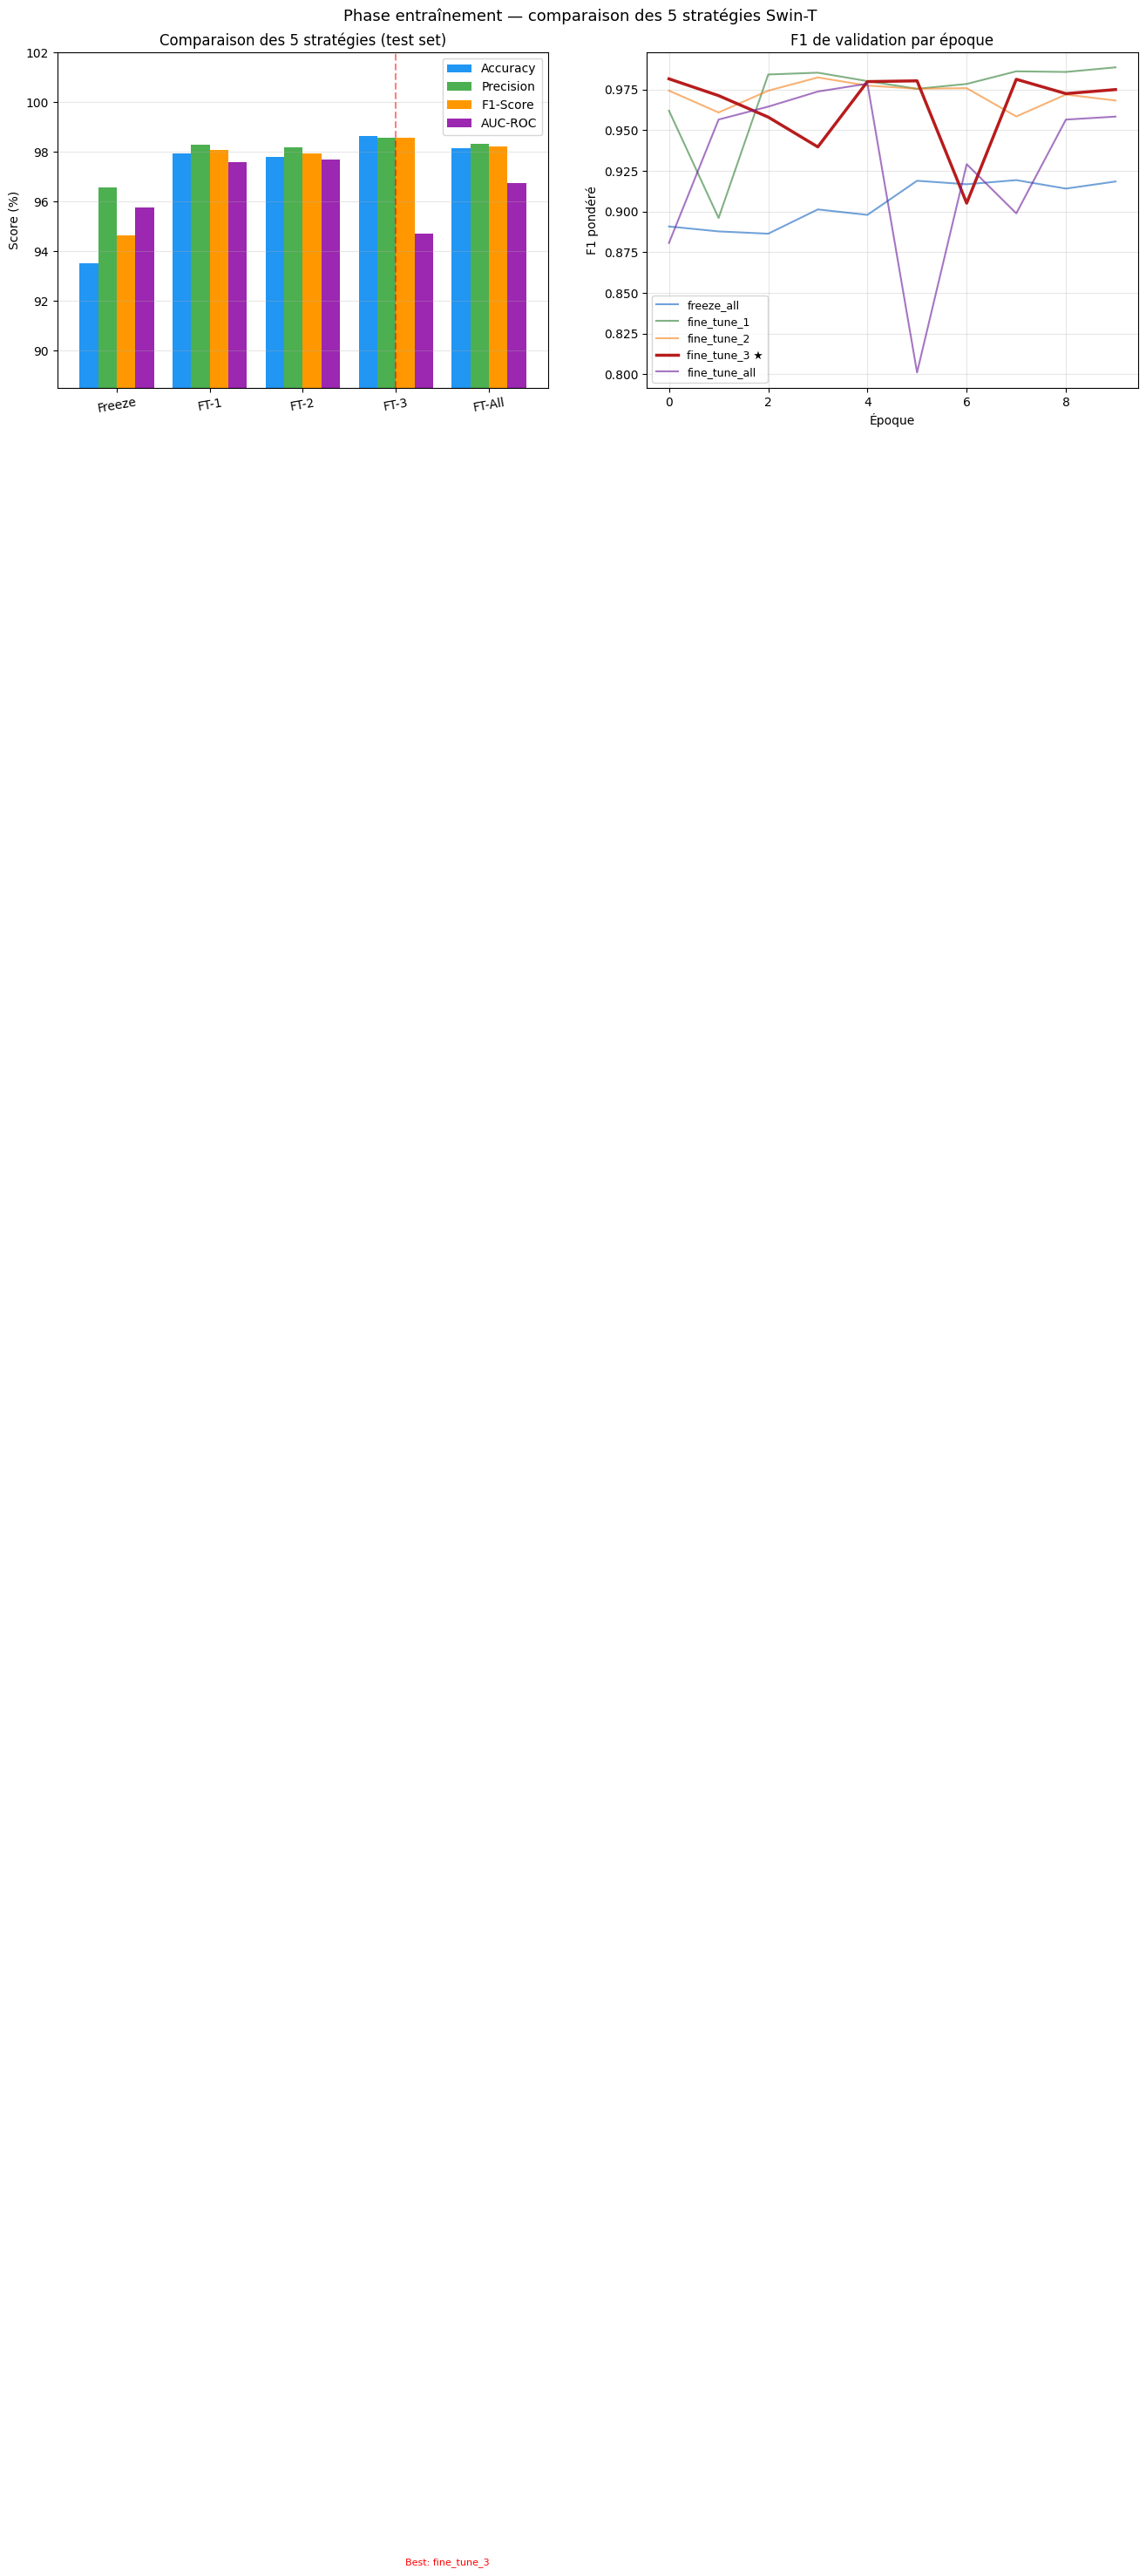

Figure sauvegardée : fig1_strategies.png


In [15]:
print("\n--- Évaluation finale après Adversarial Training ---")
 
acc_c, prec_c, rec_c, f1_c, auc_c, preds_rob, labels_rob, probs_rob = evaluate(
    robust_model, test_loader)
print(f"  [Clean après AT]  Acc={acc_c*100:.2f}%  Prec={prec_c*100:.2f}%  "
      f"Rec={rec_c*100:.2f}%  F1={f1_c*100:.2f}%  AUC={auc_c:.4f}")
 
fgsm_after = eval_adversarial(robust_model, test_loader, fgsm_attack,
                               "FGSM après AT", eps=EPS)
pgd_after  = eval_adversarial(robust_model, test_loader, pgd_attack,
                               "PGD  après AT", eps=EPS, alpha=ALPHA, steps=STEPS)
 
 
# ── Figure 1 : Comparaison des 5 stratégies ───────────────────────────────────
fig1, axes1 = plt.subplots(1, 2, figsize=(16, 5))
 
strats   = list(all_results.keys())
labels_s = ["Freeze", "FT-1", "FT-2", "FT-3", "FT-All"]
accs  = [all_results[s]["metrics"]["accuracy"]  * 100 for s in strats]
precs = [all_results[s]["metrics"]["precision"] * 100 for s in strats]
f1s   = [all_results[s]["metrics"]["f1"]        * 100 for s in strats]
aucs  = [all_results[s]["metrics"]["auc"]       * 100 for s in strats]
 
x = np.arange(len(strats)); w = 0.2
ax = axes1[0]
ax.bar(x - 1.5*w, accs,  w, label="Accuracy",  color="#2196F3")
ax.bar(x - 0.5*w, precs, w, label="Precision", color="#4CAF50")
ax.bar(x + 0.5*w, f1s,   w, label="F1-Score",  color="#FF9800")
ax.bar(x + 1.5*w, aucs,  w, label="AUC-ROC",   color="#9C27B0")
ax.set_xticks(x); ax.set_xticklabels(labels_s, rotation=10)
 
# Marquer le meilleur
best_idx = strats.index(best_strat)
ax.axvline(best_idx, color="red", linestyle="--", linewidth=1.5, alpha=0.5)
ax.text(best_idx + 0.1, ax.get_ylim()[0] + 1,
        f"Best: {best_strat}", color="red", fontsize=8)
 
ax.set_title("Comparaison des 5 stratégies (test set)", fontsize=12)
ax.set_ylabel("Score (%)"); ax.legend(); ax.grid(axis="y", alpha=0.3)
ymin = max(0, min(accs + precs + f1s + aucs) - 5)
ax.set_ylim(ymin, 102)
 
# Courbes F1 de validation
ax2 = axes1[1]
palette = ["#1565C0", "#2E7D32", "#F57F17", "#B71C1C", "#6A1B9A"]
for idx, strat in enumerate(strats):
    lw    = 2.5 if strat == best_strat else 1.5
    alpha = 1.0 if strat == best_strat else 0.6
    ax2.plot(all_results[strat]["history"]["val_f1"],
             label=strat + (" ★" if strat == best_strat else ""),
             color=palette[idx], linewidth=lw, alpha=alpha)
ax2.set_title("F1 de validation par époque", fontsize=12)
ax2.set_xlabel("Époque"); ax2.set_ylabel("F1 pondéré")
ax2.legend(fontsize=9); ax2.grid(alpha=0.3)
 
fig1.suptitle("Phase entraînement — comparaison des 5 stratégies Swin-T", fontsize=13)
plt.tight_layout()
plt.savefig("fig1_strategies.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure sauvegardée : fig1_strategies.png")

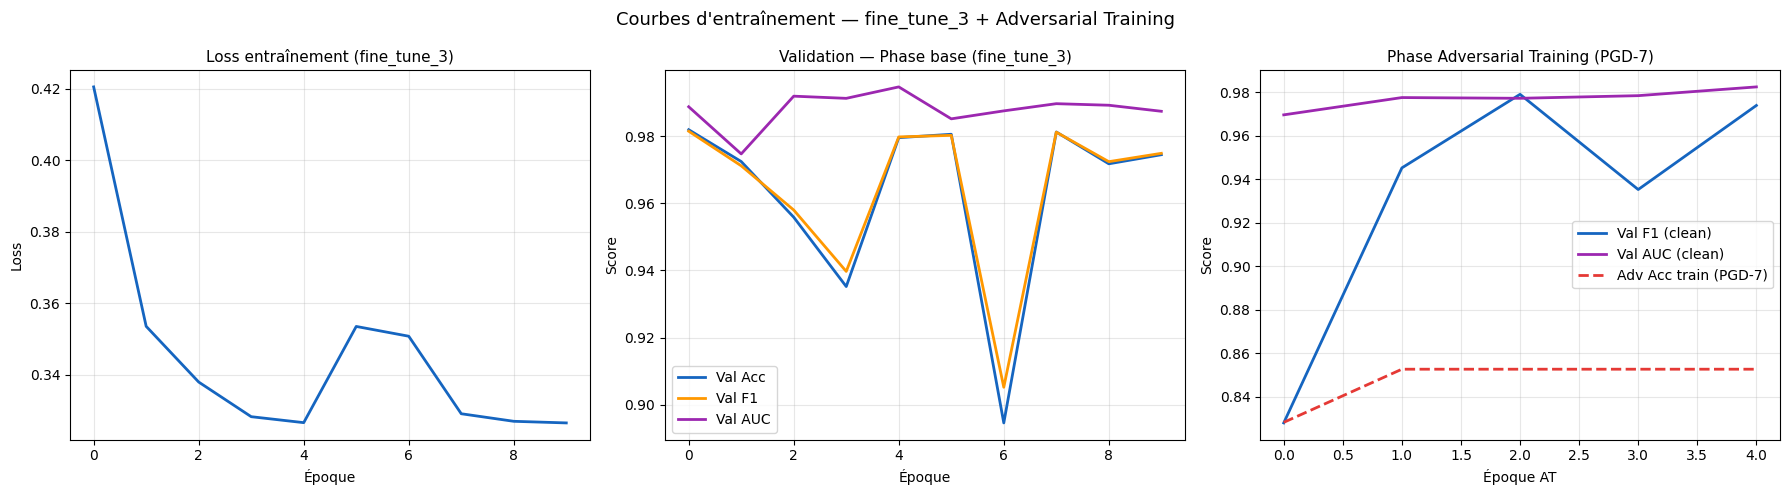

Figure sauvegardée : fig2_training_curves.png


In [16]:
# ── Figure 2 : Courbes d'entraînement du meilleur modèle + phase AT ──────────
fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
 
axes2[0].plot(all_results[best_strat]["history"]["train_loss"],
              color="#1565C0", linewidth=2)
axes2[0].set_title(f"Loss entraînement ({best_strat})", fontsize=11)
axes2[0].set_xlabel("Époque"); axes2[0].set_ylabel("Loss")
axes2[0].grid(alpha=0.3)
 
ax = axes2[1]
ax.plot(all_results[best_strat]["history"]["val_acc"],
        color="#1565C0", linewidth=2, label="Val Acc")
ax.plot(all_results[best_strat]["history"]["val_f1"],
        color="#FF9800", linewidth=2, label="Val F1")
ax.plot(all_results[best_strat]["history"]["val_auc"],
        color="#9C27B0", linewidth=2, label="Val AUC")
ax.set_title(f"Validation — Phase base ({best_strat})", fontsize=11)
ax.set_xlabel("Époque"); ax.set_ylabel("Score")
ax.legend(); ax.grid(alpha=0.3)
 
ax = axes2[2]
ax.plot(at_history["val_f1"],        color="#1565C0", linewidth=2,
        label="Val F1 (clean)")
ax.plot(at_history["val_auc"],       color="#9C27B0", linewidth=2,
        label="Val AUC (clean)")
ax.plot(at_history["adv_acc_train"], color="#E53935", linewidth=2,
        linestyle="--", label="Adv Acc train (PGD-7)")
ax.set_title("Phase Adversarial Training (PGD-7)", fontsize=11)
ax.set_xlabel("Époque AT"); ax.set_ylabel("Score")
ax.legend(); ax.grid(alpha=0.3)
 
fig2.suptitle(f"Courbes d'entraînement — {best_strat} + Adversarial Training",
              fontsize=13)
plt.tight_layout()
plt.savefig("fig2_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure sauvegardée : fig2_training_curves.png")

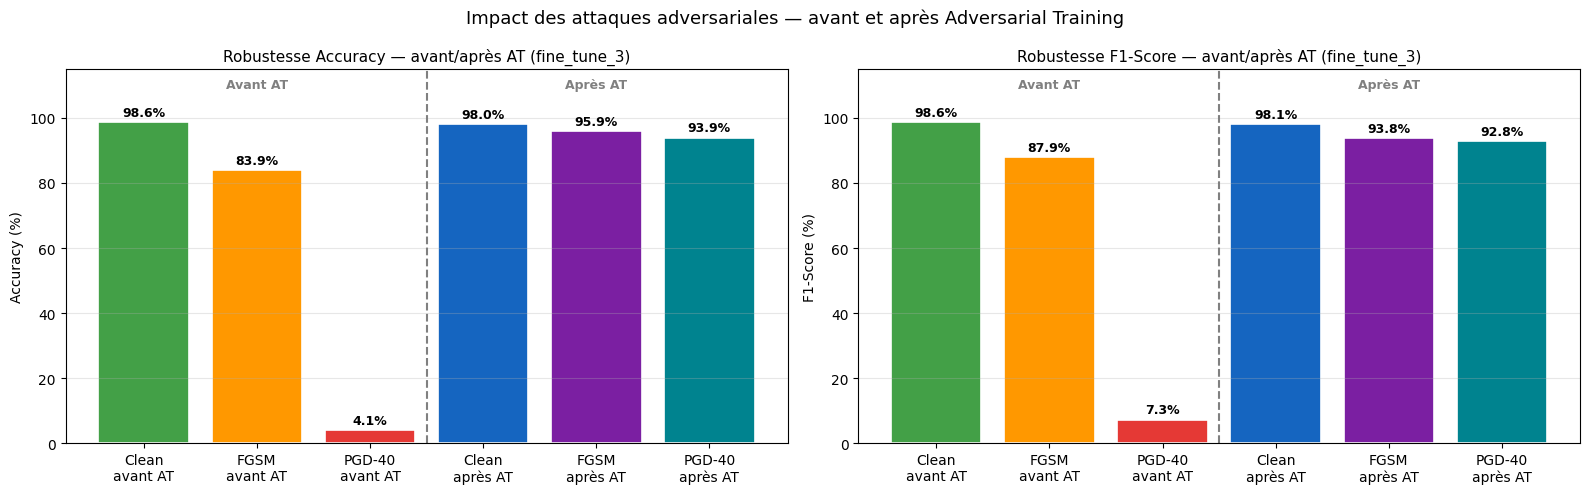

Figure sauvegardée : fig3_robustesse.png


In [17]:
# ── Figure 3 : Robustesse avant / après AT ────────────────────────────────────
fig3, axes3 = plt.subplots(1, 2, figsize=(16, 5))
 
scenarios = [
    "Clean\navant AT", "FGSM\navant AT", "PGD-40\navant AT",
    "Clean\naprès AT", "FGSM\naprès AT", "PGD-40\naprès AT",
]
vals_acc = [
    best_metrics["accuracy"]*100, fgsm_before["accuracy"]*100, pgd_before["accuracy"]*100,
    acc_c*100,                    fgsm_after["accuracy"]*100,  pgd_after["accuracy"]*100,
]
vals_f1 = [
    best_metrics["f1"]*100, fgsm_before["f1"]*100, pgd_before["f1"]*100,
    f1_c*100,               fgsm_after["f1"]*100,  pgd_after["f1"]*100,
]
bar_colors = ["#43A047", "#FF9800", "#E53935",
              "#1565C0", "#7B1FA2", "#00838F"]
 
for ax, vals, metric in zip(axes3, [vals_acc, vals_f1], ["Accuracy", "F1-Score"]):
    bars = ax.bar(scenarios, vals, color=bar_colors, edgecolor="white", linewidth=1.2)
    ax.set_title(f"Robustesse {metric} — avant/après AT ({best_strat})", fontsize=11)
    ax.set_ylabel(f"{metric} (%)")
    ax.set_ylim(0, 115)
    ax.grid(axis="y", alpha=0.3)
    ax.axvline(2.5, color="gray", linestyle="--", linewidth=1.5)
    ax.text(1.0, 109, "Avant AT", ha="center", fontsize=9,
            color="gray", fontweight="bold")
    ax.text(4.0, 109, "Après AT", ha="center", fontsize=9,
            color="gray", fontweight="bold")
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 1,
                f"{v:.1f}%", ha="center", va="bottom", fontsize=9, fontweight="bold")
 
fig3.suptitle("Impact des attaques adversariales — avant et après Adversarial Training",
              fontsize=13)
plt.tight_layout()
plt.savefig("fig3_robustesse.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure sauvegardée : fig3_robustesse.png")
 

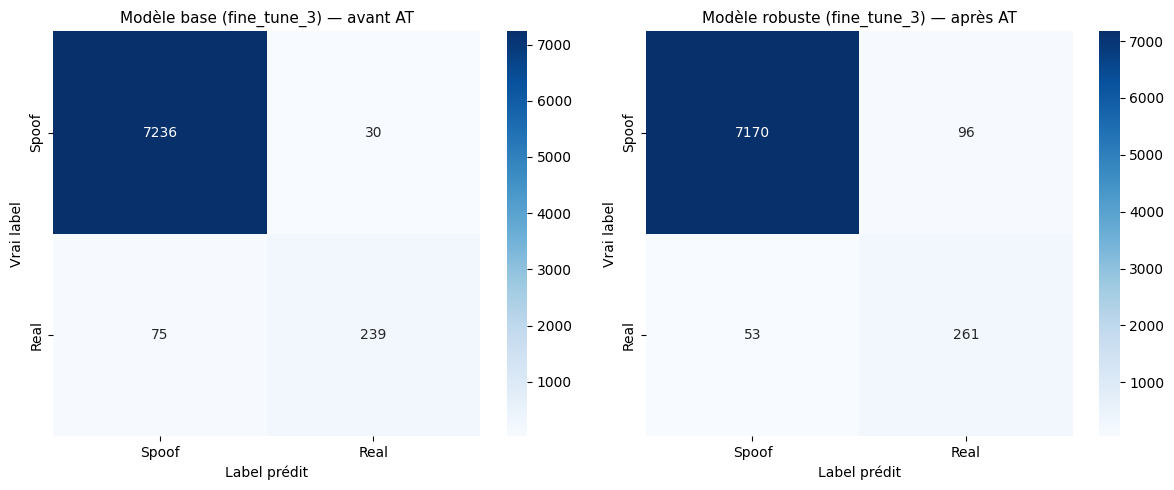

Figure sauvegardée : fig4_confusion.png


In [18]:
# ── Figure 4 : Matrices de confusion (avant AT / après AT) ───────────────────
fig4, axes4 = plt.subplots(1, 2, figsize=(12, 5))
 
for ax, preds, true_labels, title in zip(
    axes4,
    [best_metrics["preds"],  preds_rob],
    [best_metrics["labels"], labels_rob],
    [f"Modèle base ({best_strat}) — avant AT",
     f"Modèle robuste ({best_strat}) — après AT"]
):
    cm = confusion_matrix(true_labels, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Spoof", "Real"], yticklabels=["Spoof", "Real"])
    ax.set_title(title, fontsize=11)
    ax.set_ylabel("Vrai label"); ax.set_xlabel("Label prédit")
 
plt.tight_layout()
plt.savefig("fig4_confusion.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure sauvegardée : fig4_confusion.png")
 

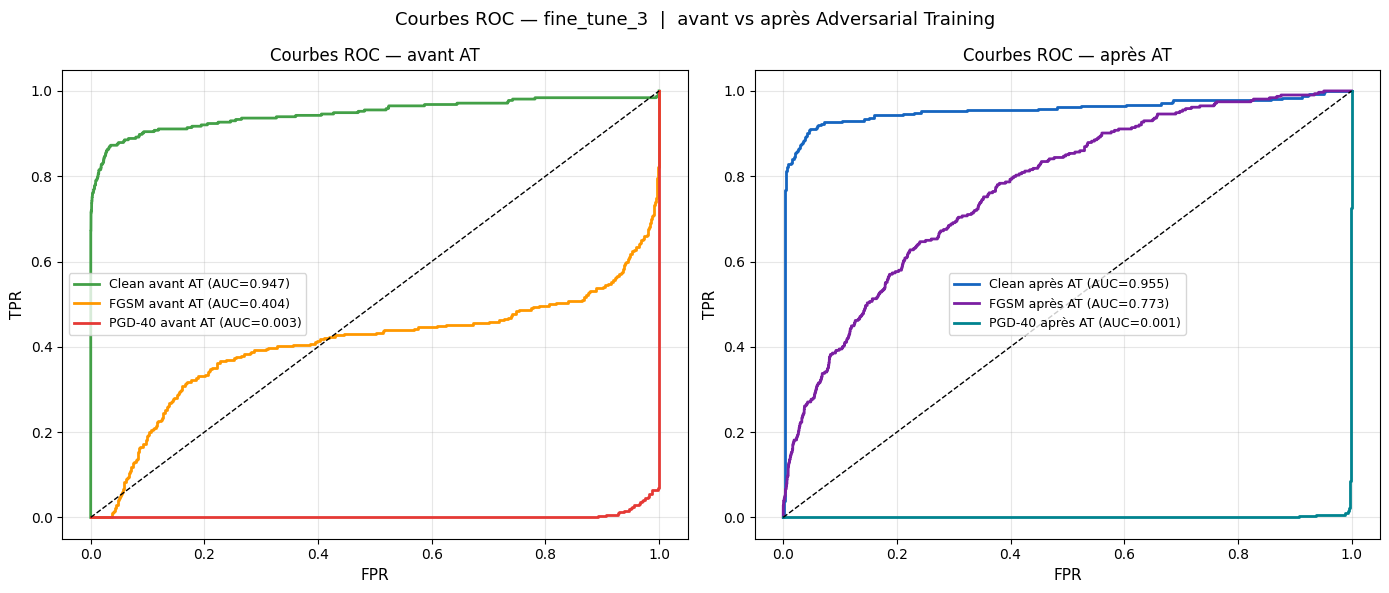

Figure sauvegardée : fig5_roc.png


In [19]:
# ── Figure 5 : Courbes ROC (avant AT vs après AT) ────────────────────────────
fig5, axes5 = plt.subplots(1, 2, figsize=(14, 6))
 
# Avant AT
ax = axes5[0]
roc_before = [
    ("Clean avant AT",  best_metrics["labels"], best_metrics["probs"], "#43A047"),
    ("FGSM avant AT",   fgsm_before["labels"],  fgsm_before["probs"],  "#FF9800"),
    ("PGD-40 avant AT", pgd_before["labels"],   pgd_before["probs"],   "#E53935"),
]
for name, lbls, prbs, color in roc_before:
    try:
        fpr, tpr, _ = roc_curve(lbls, prbs)
        auc_val     = roc_auc_score(lbls, prbs)
        ax.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.3f})",
                color=color, linewidth=2)
    except Exception:
        pass
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set_xlabel("FPR", fontsize=11); ax.set_ylabel("TPR", fontsize=11)
ax.set_title("Courbes ROC — avant AT", fontsize=12)
ax.legend(fontsize=9); ax.grid(alpha=0.3)
 
# Après AT
ax = axes5[1]
roc_after = [
    ("Clean après AT",  labels_rob,           probs_rob,            "#1565C0"),
    ("FGSM après AT",   fgsm_after["labels"], fgsm_after["probs"],  "#7B1FA2"),
    ("PGD-40 après AT", pgd_after["labels"],  pgd_after["probs"],   "#00838F"),
]
for name, lbls, prbs, color in roc_after:
    try:
        fpr, tpr, _ = roc_curve(lbls, prbs)
        auc_val     = roc_auc_score(lbls, prbs)
        ax.plot(fpr, tpr, label=f"{name} (AUC={auc_val:.3f})",
                color=color, linewidth=2)
    except Exception:
        pass
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set_xlabel("FPR", fontsize=11); ax.set_ylabel("TPR", fontsize=11)
ax.set_title("Courbes ROC — après AT", fontsize=12)
ax.legend(fontsize=9); ax.grid(alpha=0.3)
 
fig5.suptitle(f"Courbes ROC — {best_strat}  |  avant vs après Adversarial Training",
              fontsize=13)
plt.tight_layout()
plt.savefig("fig5_roc.png", dpi=150, bbox_inches="tight")
plt.show()
print("Figure sauvegardée : fig5_roc.png")
 